# 08. The basics: two problems where both tools are easy

Before looking at cases where the two approaches differ, we need a baseline.
Here are two problems that a Pyomo user would write without any trouble:

1. **Six-hump camel**: an unconstrained, polynomial, nonconvex function of two variables.
2. **Haverly pooling**: a small constrained problem with bilinear terms [haverly1978studies]; the usual global optimum is $-400$.

For each we write the model twice, once as a Pyomo `ConcreteModel` [hart2011pyomo] and once as a plain
Python function of a vector `x` using `jax.numpy`, and solve both with the same relative gap ($10^{-4}$) and a 60 s limit.
The aim is to show that the two agree, and to see what the syntax looks like in the easy case.

**What the solvers do.** All four are deterministic spatial branch and bound: they split
the variable box into smaller boxes, compute on each box a lower bound on the objective
from a convex relaxation, and discard a box once its bound is above the best feasible
value found so far (the *incumbent*). The run ends when the smallest open lower bound is
within the gap of the incumbent. SCIP [vigerske2018scip], Couenne [belotti2009branching]
and BARON [tawarmalani2005polyhedral] receive the model from Pyomo as an expression tree
(an `.nl` file for SCIP and Couenne, a GAMS file for BARON) and build linear relaxations of
each operator, McCormick envelopes [mccormick1976computability] for products among them.
jaxglobal receives a Python function, traces it to a jaxpr, and relaxes that. Neither side
asks the user for a relaxation; both need only the algebra.

BARON needs a GAMS installation. Where it is missing its row in the tables says
`not run`, and the figures leave it out.

The helper module `nbutil.py` (next to the notebooks) holds the solver wrappers and the line counter.

In [1]:
import inspect

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pyomo.environ as pyo
from matplotlib.patches import Rectangle
from scipy.optimize import linprog
from scipy.optimize import minimize as sp_minimize

import nbutil
from jaxglobal import make_bounder, minimize
from nbutil import loc, model_size, save_results, solve_jax, solve_pyomo, table

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
# one color and marker per solver, used in every figure below
STYLE = {"scip": (BLUE, "s"), "couenne": (AQUA, "D"), "baron": (YELLOW, "^"), "jaxglobal": (ORANGE, "o")}
PYOMO_SOLVERS = ("scip", "couenne", "baron")


def ran(row):
    """True when the solver ran and returned a feasible point."""
    return np.isfinite(row["obj"])


print(inspect.getsource(nbutil.loc))

def loc(*objs):
    """Count lines of model code: source lines minus blank lines, comments and docstrings."""
    n = 0
    for o in objs:
        src = inspect.getsource(o)
        src = re.sub(r'("""|\'\'\')(.*?)\1', "", src, flags=re.S)  # drop docstrings
        n += sum(1 for ln in src.splitlines() if ln.strip() and not ln.strip().startswith("#"))
    return n



`loc` counts the lines of a model-building function, skipping blank lines, comments and docstrings.
It is used for every comparison in this series. It counts *model code only*: not imports, not the solver call, not result printing.

## 1. Six-hump camel

The six-hump camel function (Dixon and Szegő, 1978; see [surjanovic2013virtual]) is

$$ f(x_1,x_2) = \left(4 - 2.1x_1^2 + \tfrac{1}{3}x_1^4\right)x_1^2 + x_1x_2 + \left(-4+4x_2^2\right)x_2^2,
   \qquad x_1\in[-3,3],\ x_2\in[-2,2]. $$

It is a polynomial of degree six with no constraints other than the box. It has six local
minima. Two of them are global, $f^*=-1.031628$ at $\pm(0.0898,-0.7126)$; the function is
symmetric under $x\mapsto -x$, so every minimizer comes with a mirror image.

Why it is a test for a global solver at all: $f$ is nonconvex (the $-2.1x_1^4$ and $-4x_2^2$
terms), so a local method started in the wrong basin stops at one of the four non-global minima.
Branch and bound has a second, quieter difficulty here: because there are two global minima, the
boxes around *both* have lower bounds close to $f^*$, and neither can be discarded until each
has been bounded to within the gap. The contour plot below shows the landscape; the six local
minima are found by a local solver from a grid of starting points.

local minimum at (+0.0898, -0.7127):  f = -1.031628
local minimum at (-0.0898, +0.7127):  f = -1.031628
local minimum at (-1.7036, +0.7961):  f = -0.215464
local minimum at (+1.7036, -0.7961):  f = -0.215464
local minimum at (-1.6071, -0.5687):  f = 2.104250
local minimum at (+1.6071, +0.5687):  f = 2.104250


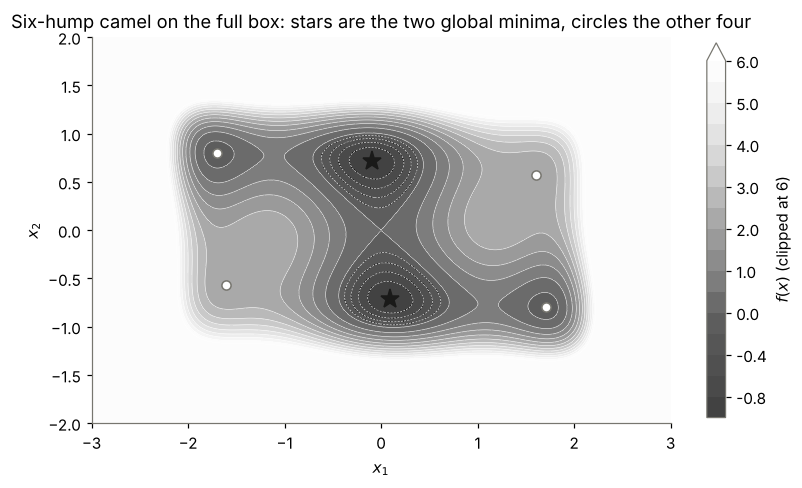

In [2]:
def camel_np(a, b):
    return (4 - 2.1 * a**2 + a**4 / 3) * a**2 + a * b + (-4 + 4 * b**2) * b**2


starts = [(a, b) for a in np.linspace(-2.5, 2.5, 7) for b in np.linspace(-1.5, 1.5, 7)]
local_min = []
for s in starts:
    r = sp_minimize(lambda z: camel_np(*z), s, bounds=[(-3, 3), (-2, 2)], method="L-BFGS-B")
    H = np.asarray(jax.hessian(lambda z: camel_np(z[0], z[1]))(jnp.asarray(r.x)))
    is_min = np.linalg.eigvalsh(H).min() > 0  # a start on a saddle (the origin) stays there
    if is_min and not any(np.allclose(r.x, q, atol=1e-3) for q, _ in local_min):
        local_min.append((r.x, r.fun))
local_min.sort(key=lambda t: t[1])
for q, v in local_min:
    print(f"local minimum at ({q[0]:+.4f}, {q[1]:+.4f}):  f = {v:.6f}")

G1, G2 = np.meshgrid(np.linspace(-3, 3, 400), np.linspace(-2, 2, 300))
FG = camel_np(G1, G2)


def camel_axes(ax, levels=None):
    """Filled contours of the camel function (clipped at f = 6 so the basins stay visible)."""
    if levels is None:
        levels = np.concatenate([np.linspace(FG.min(), 0, 6), np.linspace(0.5, 6, 12)])
    cs = ax.contourf(G1, G2, np.minimum(FG, 6), levels=levels, cmap="Greys_r", alpha=0.75, extend="max")
    ax.contour(G1, G2, FG, levels=levels, colors="white", linewidths=0.4)
    for q, v in local_min:
        glob = v < local_min[0][1] + 1e-6
        ax.plot(*q, "*" if glob else "o", color=INK if glob else MUTED, ms=13 if glob else 6, mfc="white" if not glob else INK)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
    ax.grid(False)
    return cs


fig, ax = plt.subplots(figsize=(7.5, 4.6))
cs = camel_axes(ax)
fig.colorbar(cs, ax=ax, shrink=0.85, label="$f(x)$ (clipped at 6)", format="%.1f")
ax.set_title("Six-hump camel on the full box: stars are the two global minima, circles the other four")
plt.tight_layout()
plt.show()

In Pyomo the variables, their bounds and the objective are separate components of a model
object; in JAX the objective is a function and the bounds are arguments of the solver call.

In [3]:
def camel_pyomo():
    m = pyo.ConcreteModel()
    m.x1 = pyo.Var(bounds=(-3, 3), initialize=0.5)
    m.x2 = pyo.Var(bounds=(-2, 2), initialize=0.5)
    m.obj = pyo.Objective(
        expr=(4 - 2.1 * m.x1**2 + m.x1**4 / 3) * m.x1**2 + m.x1 * m.x2 + (-4 + 4 * m.x2**2) * m.x2**2
    )
    return m

In [4]:
def camel(x):
    a, b = x[0], x[1]
    return (4 - 2.1 * a**2 + a**4 / 3) * a**2 + a * b + (-4 + 4 * b**2) * b**2

The two bodies are nearly the same expression. The Pyomo version needs the model object, the declaration of each variable and its bounds, and the `Objective` wrapper;
the JAX version takes the bounds as arguments of the solver call.

Each Pyomo solver gets a fresh model; we keep the models so that the returned points can be plotted.

In [5]:
m = camel_pyomo()
size = model_size(m)
camel_models = {s: camel_pyomo() for s in PYOMO_SOLVERS}
rows = [solve_pyomo(camel_models[s], s) for s in PYOMO_SOLVERS]
rows.append(solve_jax(camel, [-3, -2], [3, 2]))  # first call includes JIT compilation
rows.append({**solve_jax(camel, [-3, -2], [3, 2]), "solver": "jaxglobal (2nd call, cached)"})
t = table(rows)
t

,solver,obj,bound,time,status
0,scip,-1.031628,-1.031711,0.20,optimal
1,couenne,-1.031628,NaN,0.22,optimal
2,baron,NaN,NaN,NaN,not run: GAMS/BARON not installed
3,jaxglobal,-1.031628,-1.031691,1.14,optimal
4,"jaxglobal (2nd call, cached)",-1.031628,-1.031691,0.20,optimal


In [6]:
save_results("08", "six-hump camel", loc(camel_pyomo), loc(camel), size, rows)
print(f"lines of model code: Pyomo {loc(camel_pyomo)}, jaxglobal {loc(camel)};  Pyomo model size: {size[0]} vars, {size[1]} constraints")
print("jaxglobal minimizer:", rows[3]["x"], " (literature: +-(0.0898, -0.7126))")
camel_rows = rows

lines of model code: Pyomo 8, jaxglobal 3;  Pyomo model size: 2 vars, 0 constraints
jaxglobal minimizer: [-0.08984201  0.7126564 ]  (literature: +-(0.0898, -0.7126))


Every solver that ran finds $-1.031628$. Notes on the columns:

* *obj* is the best feasible value found; *bound* is the proven lower bound. Couenne's `.nl` interface does not return its final bound to Pyomo, so it is blank. SCIP's comes back through the `.nl` solution, as part of the solve message for the classic SCIP binary and as a `bestbound` suffix for the AMPL MP build (`nbutil.solve_pyomo` handles both).
* Times are wall-clock for the whole call: for Pyomo solvers that includes writing the model file and starting the solver process; for jaxglobal the first call includes tracing and XLA compilation (the second call reuses the compiled kernels). The machine is loaded by other work, so only large ratios mean anything.
* `status` is whatever each solver reports. For SCIP we map "gap limit reached" (when that build reports it) to `optimal`, since the $10^{-4}$ relative gap is the stopping criterion we set.

**Which minimizer?** The two global minima have the same value, so a solver may return
either one; both answers are correct. The figure zooms in on the two global minima and
marks the point each solver returned.

scip       x = (+0.08979, -0.71253)   f(x) = -1.031628
couenne    x = (-0.08984, +0.71266)   f(x) = -1.031628
jaxglobal  x = (-0.08984, +0.71266)   f(x) = -1.031628


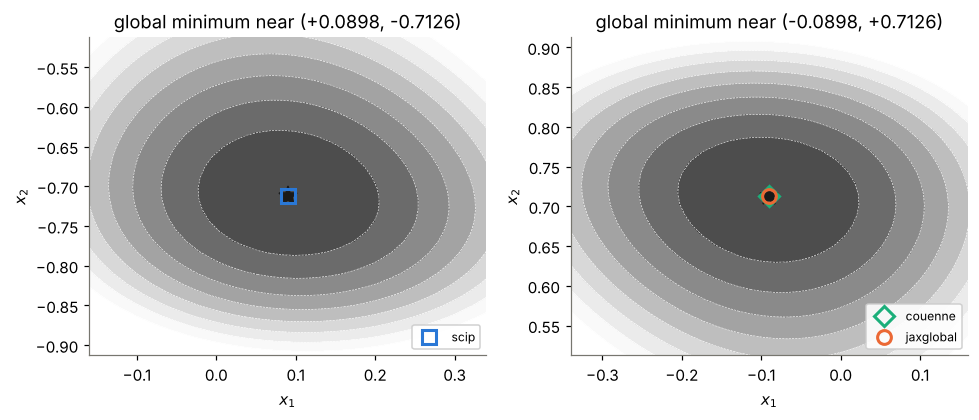

In [7]:
camel_x = {s: np.array([pyo.value(camel_models[s].x1), pyo.value(camel_models[s].x2)])
           for s, r in zip(PYOMO_SOLVERS, rows) if ran(r)}
camel_x["jaxglobal"] = np.asarray(rows[3]["x"])
for s, x in camel_x.items():
    print(f"{s:10s} x = ({x[0]:+.5f}, {x[1]:+.5f})   f(x) = {camel_np(*x):.6f}")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, sign in zip(axs, (1, -1)):
    camel_axes(ax, levels=np.linspace(local_min[0][1], local_min[0][1] + 0.4, 9))
    c = sign * np.array([0.0898, -0.7126])
    ax.set_xlim(c[0] - 0.25, c[0] + 0.25)
    ax.set_ylim(c[1] - 0.2, c[1] + 0.2)
    for s, x in camel_x.items():
        if np.linalg.norm(x - c) < 0.2:
            col, mk = STYLE[s]
            ax.plot(*x, mk, color=col, ms=9, mfc="none", mew=2, label=s)
    ax.set_title(f"global minimum near ({c[0]:+.4f}, {c[1]:+.4f})")
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="lower right", fontsize=8, framealpha=0.9)
plt.tight_layout()
plt.show()

### How jaxglobal closes the gap

`minimize` records, at each iteration of its search, the number of boxes bounded so far,
the smallest lower bound over the open boxes, and the incumbent (`Result.history`). A second
call with the same function and settings reuses the compiled kernels, so it is cheap to
repeat the solve and look at the record. The incumbent is found almost at once by the
local solver; nearly all of the work is spent raising the lower bound until it meets it.

Result(status='optimal', fun=-1.0316285, lower_bound=-1.0316911, gap=6.26e-05, x=[-0.089842  0.712656], nodes=21, iterations=6, time=0.22s)


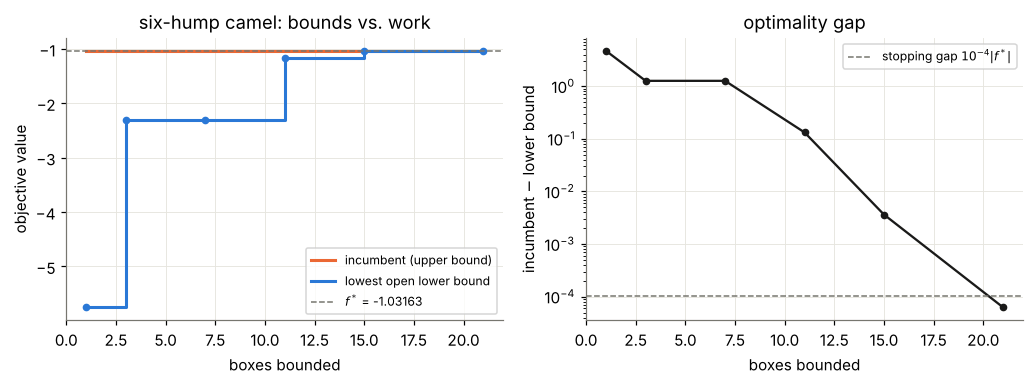

In [8]:
def history_plot(ax, res, fstar, title):
    h = np.array(res.history)
    nodes, lb, ub = h[:, 1], h[:, 2], h[:, 3]
    ax.step(nodes, ub, where="post", color=ORANGE, lw=2, label="incumbent (upper bound)")
    ax.step(nodes, lb, where="post", color=BLUE, lw=2, label="lowest open lower bound")
    ax.plot(nodes, lb, "o", color=BLUE, ms=4)
    ax.axhline(fstar, color=MUTED, lw=1, ls="--", label=f"$f^*$ = {fstar:g}")
    ax.set_xlabel("boxes bounded")
    ax.set_ylabel("objective value")
    ax.set_title(title)
    ax.legend(fontsize=8)


res_camel = minimize(camel, np.array([-3.0, -2.0]), np.array([3.0, 2.0]), rel_tol=nbutil.GAP, abs_tol=1e-6,
                     time_limit=nbutil.TIME_LIMIT)
print(res_camel)
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.6))
history_plot(axs[0], res_camel, -1.031628, "six-hump camel: bounds vs. work")
h = np.array(res_camel.history)
axs[1].semilogy(h[:, 1], np.maximum(h[:, 3] - h[:, 2], 1e-12), "o-", color=INK, lw=1.5, ms=4)
axs[1].axhline(nbutil.GAP * abs(res_camel.fun), color=MUTED, ls="--", lw=1, label=r"stopping gap $10^{-4}|f^*|$")
axs[1].set_xlabel("boxes bounded")
axs[1].set_ylabel("incumbent $-$ lower bound")
axs[1].set_title("optimality gap")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Why the bound on a box improves as the box shrinks.** The lower bound on a box comes from a
convex underestimator of $f$ on that box, and the error of such an underestimator shrinks
with the box width (notebook 01). The figure below makes this concrete without running the
search: it splits the box into uniform grids of $4\times4$, $8\times8$ and $16\times16$
cells and bounds every cell with jaxglobal's batched bounder `make_bounder`, using the same
relaxations `minimize` uses by default (McCormick with univariate envelopes and αBB, but
without the bound tightening and cuts `minimize` adds). A cell whose lower bound is above
$f^*$ cannot contain a global minimum, and branch and bound would discard it. Cells left
coloured are the ones that still have to be split. They cluster around the two global
minima, which is why the search above ends with a handful of small boxes around both.

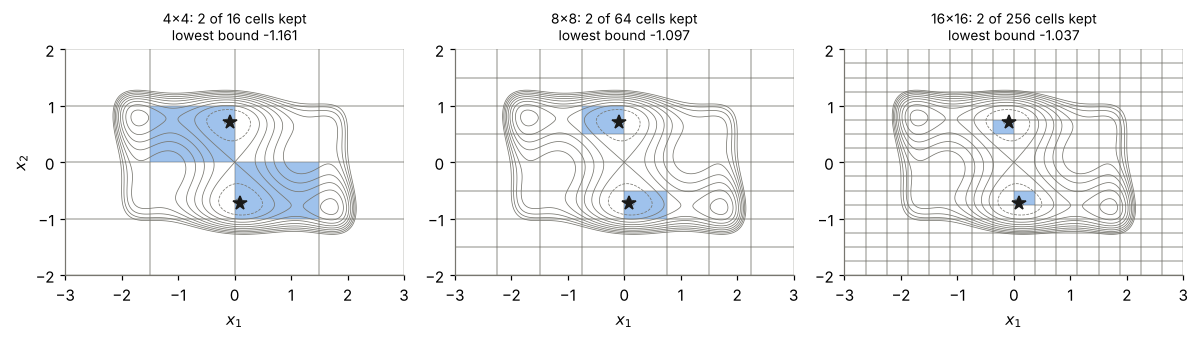

In [9]:
bound_batch = jax.jit(jax.vmap(make_bounder(camel, univariate=True, alphabb=True)))
LEVELS = (4, 8, 16)
cells_lo, cells_hi = [], []
for k in LEVELS:
    e1, e2 = np.linspace(-3, 3, k + 1), np.linspace(-2, 2, k + 1)
    for i in range(k):
        for j in range(k):
            cells_lo.append([e1[i], e2[j]])
            cells_hi.append([e1[i + 1], e2[j + 1]])
cells_lo, cells_hi = np.array(cells_lo), np.array(cells_hi)
cell_lb = np.asarray(bound_batch(jnp.asarray(cells_lo), jnp.asarray(cells_hi))[0])  # one call, one compile

FSTAR = local_min[0][1]
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
start = 0
for ax, k in zip(axs, LEVELS):
    sl = slice(start, start + k * k)
    start += k * k
    ax.contour(G1, G2, FG, levels=np.linspace(-1, 4, 11), colors=MUTED, linewidths=0.5)
    keep = cell_lb[sl] <= FSTAR
    for lo_, hi_, kp in zip(cells_lo[sl], cells_hi[sl], keep):
        ax.add_patch(Rectangle(lo_, *(hi_ - lo_), facecolor=BLUE if kp else "none", alpha=0.45 if kp else 1,
                               edgecolor=MUTED, lw=0.3))
    for q, v in local_min[:2]:
        ax.plot(*q, "*", color=INK, ms=9)
    ax.set_xlim(-3, 3)
    ax.set_ylim(-2, 2)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("$x_1$")
    ax.set_title(f"{k}x{k}: {keep.sum()} of {k * k} cells kept\nlowest bound {cell_lb[sl].min():.3f}", fontsize=9)
axs[0].set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

## 2. Haverly pooling problem

Pooling problems come from refinery and blending operations: streams of different quality are
mixed in a tank (the *pool*), and the mixture is then sent on to products that must meet a
quality specification. Haverly's instance [haverly1978studies] (see also [floudas1999handbook])
is the smallest one with the essential difficulty.

Two sources A (3% sulfur, cost 6) and B (1%, cost 16) feed a pool; the pool blends with a direct
feed C (2%, cost 10) into products x (max 2.5% sulfur, price 9, demand $\le 100$) and y (max 1.5%,
price 15, demand $\le 200$). The diagram shows the flows, which are the decision variables.

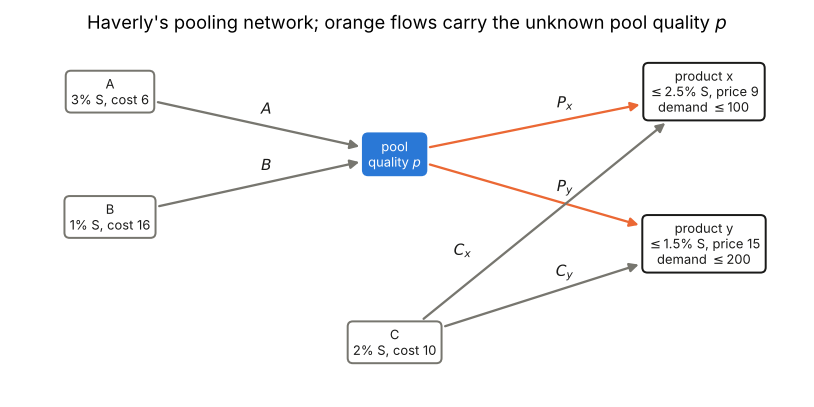

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.set_axis_off()
ax.set_xlim(-0.8, 5.6)
ax.set_ylim(-1.1, 2.9)
nodes_xy = {"A": (0, 2.3), "B": (0, 0.9), "C": (2.3, -0.5), "pool": (2.3, 1.6), "x": (4.8, 2.3), "y": (4.8, 0.6)}
labels = {"A": "A\n3% S, cost 6", "B": "B\n1% S, cost 16", "C": "C\n2% S, cost 10", "pool": "pool\nquality $p$",
          "x": "product x\n$\\leq$2.5% S, price 9\ndemand $\\leq$100", "y": "product y\n$\\leq$1.5% S, price 15\ndemand $\\leq$200"}
txt = {}
for k, (px, py) in nodes_xy.items():
    col = BLUE if k == "pool" else (MUTED if k in "ABC" else INK)
    txt[k] = ax.text(px, py, labels[k], ha="center", va="center", fontsize=8.5, color="white" if k == "pool" else INK,
                     bbox=dict(boxstyle="round,pad=0.4", fc=col if k == "pool" else "white", ec=col, lw=1.3))
fig.canvas.draw()  # the boxes need a size before arrows can be clipped to them
for a, b, lab in [("A", "pool", "$A$"), ("B", "pool", "$B$"), ("pool", "x", "$P_x$"), ("pool", "y", "$P_y$"),
                  ("C", "x", "$C_x$"), ("C", "y", "$C_y$")]:
    ax.annotate("", xy=nodes_xy[b], xytext=nodes_xy[a],
                arrowprops=dict(arrowstyle="-|>", color=ORANGE if a == "pool" else MUTED, lw=1.5, mutation_scale=12,
                                patchA=txt[a].get_bbox_patch(), patchB=txt[b].get_bbox_patch(), shrinkA=2, shrinkB=2))
    (x0, y0), (x1, y1) = nodes_xy[a], nodes_xy[b]
    w, dx = (0.7, -0.2) if lab == "$C_x$" else (0.45, 0)  # keep the C_x label clear of the P_y arrow
    ax.text(w * x0 + (1 - w) * x1 + dx, w * y0 + (1 - w) * y1 + 0.13, lab, ha="center", fontsize=10, color=INK)
ax.set_title("Haverly's pooling network; orange flows carry the unknown pool quality $p$")
plt.tight_layout()
plt.show()

With $p$ the sulfur percentage in the pool, the model is

$$
\begin{aligned}
\min\quad & -(9x + 15y) + 6A + 16B + 10(C_x + C_y) \\
\text{s.t.}\quad & P_x + P_y = A + B && \text{(pool mass balance)}\\
& x = P_x + C_x,\qquad y = P_y + C_y && \text{(product balances)}\\
& p\,(P_x + P_y) = 3A + B && \text{(sulfur balance of the pool)}\\
& p\,P_x + 2C_x \le 2.5\,x,\qquad p\,P_y + 2C_y \le 1.5\,y && \text{(product specifications)}\\
& 0\le A,B,P_x,P_y\le 300,\quad 0\le C_x,x\le 100,\quad 0\le C_y,y\le 200,\quad 0\le p\le 3.
\end{aligned}
$$

Nine variables, four equalities, two inequalities. Pooling means the sulfur concentration of
the pool $p$ is a variable, so the quality balances contain the products $p\,P_x$ and $p\,P_y$,
which are bilinear. This is the standard formulation used in `jaxglobal/problems.py`, with the
standard global optimum $-400$.

**Why it is hard.** The bilinear terms make the feasible set nonconvex, and the problem has a
non-global local optimum: a local NLP solver can stop there, depending on its starting point.
A useful way to see the structure: *for fixed $p$ every constraint is linear*, so the best
profit at a given pool quality is a linear program. The curve of that LP value against $p$
is the problem projected onto its one "complicating" variable.

In [11]:
def haverly_lp(p):
    """Best objective of the Haverly problem with the pool quality fixed at p (a linear program)."""
    # variables: A, B, Cx, Cy, Px, Py, x, y
    c = [6, 16, 10, 10, 0, 0, -9, -15]
    A_eq = [[-1, -1, 0, 0, 1, 1, 0, 0], [0, 0, -1, 0, -1, 0, 1, 0], [0, 0, 0, -1, 0, -1, 0, 1], [-3, -1, 0, 0, p, p, 0, 0]]
    A_ub = [[0, 0, 2, 0, p, 0, -2.5, 0], [0, 0, 0, 2, 0, p, 0, -1.5]]
    bnds = [(0, 300), (0, 300), (0, 100), (0, 200), (0, 300), (0, 300), (0, 100), (0, 200)]
    return linprog(c, A_ub=A_ub, b_ub=[0, 0], A_eq=A_eq, b_eq=[0] * 4, bounds=bnds).fun


ps = np.linspace(0, 3, 301)
lp_val = np.array([haverly_lp(p) for p in ps])
i_glob = np.argmin(lp_val)
right = ps > 2
i_loc = np.flatnonzero(right)[np.argmin(lp_val[right])]
zero = ps[(lp_val > -1e-6) & (ps > 1) & (ps < 3)]
print(f"value 0 (nothing made) for p in [{zero.min():.2f}, {zero.max():.2f}]")
print(f"global: p = {ps[i_glob]:.2f}, objective {lp_val[i_glob]:.2f};  other local minimum: p = {ps[i_loc]:.2f}, objective {lp_val[i_loc]:.2f}")

value 0 (nothing made) for p in [1.51, 2.40]
global: p = 1.00, objective -400.00;  other local minimum: p = 3.00, objective -100.00


Below $p=1$ the sulfur balance cannot hold with nonnegative flows from A (3%) and B (1%), so
only the zero-flow solution remains and the value is 0; in the middle of the range the blend
is too sulfurous for y and too expensive for x, and again nothing is made. The two dips are the two ways to
run the pool: at $p=1$ (pure B) the pool serves the low-sulfur product y; at $p=3$ (pure A) it
serves the high-sulfur product x. The second is a local minimum, and a local solver that
reaches it has no reason to leave. A global solver has to prove that nothing in between, or on
the other side, is better.

In Pyomo we can name every constraint and give the variables names, which makes the model self-documenting.

In [12]:
def haverly_pyomo():
    m = pyo.ConcreteModel()
    m.A = pyo.Var(bounds=(0, 300), initialize=0)    # flow from source A to pool
    m.B = pyo.Var(bounds=(0, 300), initialize=0)    # flow from source B to pool
    m.Cx = pyo.Var(bounds=(0, 100), initialize=0)   # direct feed C to product x
    m.Cy = pyo.Var(bounds=(0, 200), initialize=0)   # direct feed C to product y
    m.Px = pyo.Var(bounds=(0, 300), initialize=0)   # pool to x
    m.Py = pyo.Var(bounds=(0, 300), initialize=0)   # pool to y
    m.x = pyo.Var(bounds=(0, 100), initialize=0)    # product x
    m.y = pyo.Var(bounds=(0, 200), initialize=0)    # product y
    m.p = pyo.Var(bounds=(0, 3), initialize=1)      # sulfur fraction in the pool (percent)
    m.pool_balance = pyo.Constraint(expr=m.Px + m.Py == m.A + m.B)
    m.x_balance = pyo.Constraint(expr=m.x == m.Px + m.Cx)
    m.y_balance = pyo.Constraint(expr=m.y == m.Py + m.Cy)
    m.pool_quality = pyo.Constraint(expr=m.p * (m.Px + m.Py) == 3 * m.A + m.B)
    m.x_spec = pyo.Constraint(expr=m.p * m.Px + 2 * m.Cx <= 2.5 * m.x)
    m.y_spec = pyo.Constraint(expr=m.p * m.Py + 2 * m.Cy <= 1.5 * m.y)
    m.obj = pyo.Objective(expr=-(9 * m.x + 15 * m.y - 6 * m.A - 16 * m.B - 10 * (m.Cx + m.Cy)))
    return m

In the JAX version the variables are one vector; constraints are two plain functions returning arrays, one for `<= 0` and one for `== 0`.
The names live in the tuple unpacking on the first line of each function.

In [13]:
def haverly(z):
    A, B, Cx, Cy, Px, Py, x, y, p = z
    return -(9 * x + 15 * y - 6 * A - 16 * B - 10 * (Cx + Cy))


def haverly_ineq(z):
    A, B, Cx, Cy, Px, Py, x, y, p = z
    return jnp.stack([p * Px + 2 * Cx - 2.5 * x, p * Py + 2 * Cy - 1.5 * y])


def haverly_eq(z):
    A, B, Cx, Cy, Px, Py, x, y, p = z
    return jnp.stack([Px + Py - A - B, x - Px - Cx, y - Py - Cy, p * (Px + Py) - 3 * A - B])


hlo = np.array([0.0] * 8 + [0.0])
hhi = np.array([300.0, 300, 100, 200, 300, 300, 100, 200, 3])

**What the solvers do with the bilinear terms.** Neither formulation contains a relaxation;
the solvers build one. For a product $w = p\,P$ with $p\in[p^L,p^U]$ and $P\in[P^L,P^U]$ the
tightest convex relaxation on the box is McCormick's [mccormick1976computability]:

$$
\begin{aligned}
w &\ge p^L P + P^L p - p^L P^L, & w &\ge p^U P + P^U p - p^U P^U,\\
w &\le p^U P + P^L p - p^U P^L, & w &\le p^L P + P^U p - p^L P^U.
\end{aligned}
$$

SCIP, Couenne and BARON add an auxiliary variable for each product and these four
inequalities to a linear relaxation; jaxglobal evaluates the same envelope along its jaxpr.
On the root box ($p\in[0,3]$, $P\in[0,300]$) the envelope is loose, so the root bound is far
below $-400$. The envelope is exact when either factor's range shrinks to a point, so
splitting the range of $p$ tightens it; at fixed $p$ (the LP curve above) nothing is left to relax.

In [14]:
m = haverly_pyomo()
size = model_size(m)
haverly_models = {s: haverly_pyomo() for s in PYOMO_SOLVERS}
rows = [solve_pyomo(haverly_models[s], s) for s in PYOMO_SOLVERS]
rows.append(solve_jax(haverly, hlo, hhi, ineq=haverly_ineq, eq=haverly_eq))
table(rows)

,solver,obj,bound,time,status
0,scip,-400.000002,-400.000002,0.06,optimal
1,couenne,-400.000057,NaN,0.25,optimal
2,baron,NaN,NaN,NaN,not run: GAMS/BARON not installed
3,jaxglobal,-400.000000,-400.002224,2.38,optimal


In [15]:
lp, lj = loc(haverly_pyomo), loc(haverly, haverly_ineq, haverly_eq)
save_results("08", "Haverly pooling", lp, lj, size, rows)
print(f"lines of model code: Pyomo {lp}, jaxglobal {lj};  Pyomo model size: {size[0]} vars, {size[1]} constraints")
haverly_rows = rows

lines of model code: Pyomo 19, jaxglobal 9;  Pyomo model size: 9 vars, 6 constraints


Every solver that ran returns $-400$ to within the gap. The returned flows show the operating
mode: the pool runs on B only ($p=1$) and all of it goes to product y, topped up with C; product
x is not made. The left panel marks each solver's $(p, \text{objective})$ on the LP curve; the
right panel shows jaxglobal's lower bound rising from its root value to $-400$.

solver             A        B       Cx       Cy       Px       Py        x        y        p
scip          -0.000  100.000    0.000  100.000   -0.000  100.000    0.000  200.000    1.000
couenne        0.000  100.000    0.000  100.000    0.000  100.000    0.000  200.000    1.000
jaxglobal      0.000  100.000    0.000  100.000    0.000  100.000    0.000  200.000    1.000


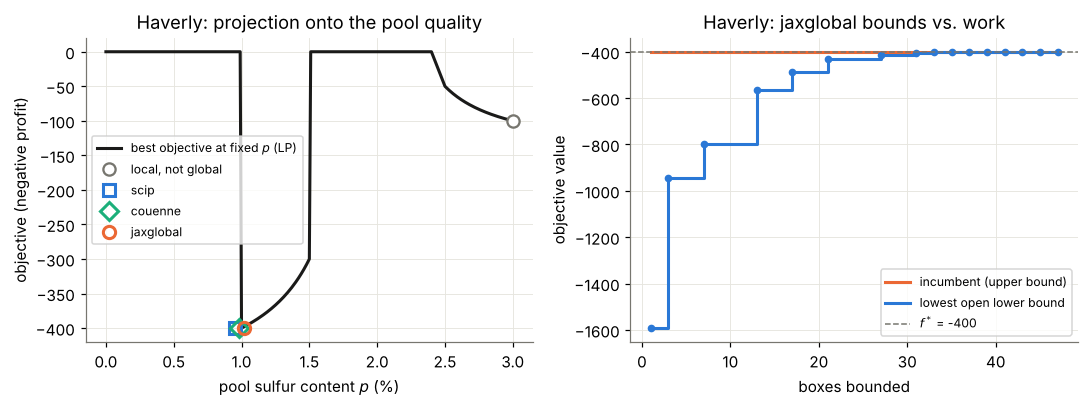

In [16]:
names = ["A", "B", "Cx", "Cy", "Px", "Py", "x", "y", "p"]
hav_x = {s: np.array([pyo.value(getattr(haverly_models[s], v)) for v in names])
         for s, r in zip(PYOMO_SOLVERS, rows) if ran(r)}
hav_x["jaxglobal"] = np.asarray(rows[3]["x"])
print("solver     " + "".join(f"{v:>9s}" for v in names))
for s, z in hav_x.items():
    print(f"{s:10s} " + "".join(f"{v:9.3f}" for v in z))

res_hav = minimize(haverly, hlo, hhi, ineq=haverly_ineq, eq=haverly_eq, rel_tol=nbutil.GAP, abs_tol=1e-6,
                   time_limit=nbutil.TIME_LIMIT)  # same settings as solve_jax; reuses the compiled kernels

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axs[0]
ax.plot(ps, lp_val, color=INK, lw=2, label="best objective at fixed $p$ (LP)")
ax.plot(ps[i_loc], lp_val[i_loc], "o", color=MUTED, ms=8, mfc="white", mew=1.5, label="local, not global")
for k, (s, z) in enumerate(hav_x.items()):
    col, mk = STYLE[s]
    ax.plot(z[8] + 0.03 * (k - 1.5), haverly(z), mk, color=col, ms=8, mfc="none", mew=2, label=s)
ax.set_xlabel("pool sulfur content $p$ (%)")
ax.set_ylabel("objective (negative profit)")
ax.set_title("Haverly: projection onto the pool quality")
ax.legend(fontsize=8, loc="center left")
history_plot(axs[1], res_hav, -400, "Haverly: jaxglobal bounds vs. work")
plt.tight_layout()
plt.show()

(The markers on the left are offset sideways a little so that they do not hide each other;
the returned values of $p$ are in the printed table above.)

## Effort: lines of code and time

The last figure collects the two tables. Line counts are from `loc`; times are wall-clock for
one call, including the model-file round trip for Pyomo and compilation for jaxglobal's
first call (the cached second call is the jaxglobal time with compilation removed; for Haverly
it is the `minimize` call made for the history plot). The time axis is logarithmic.

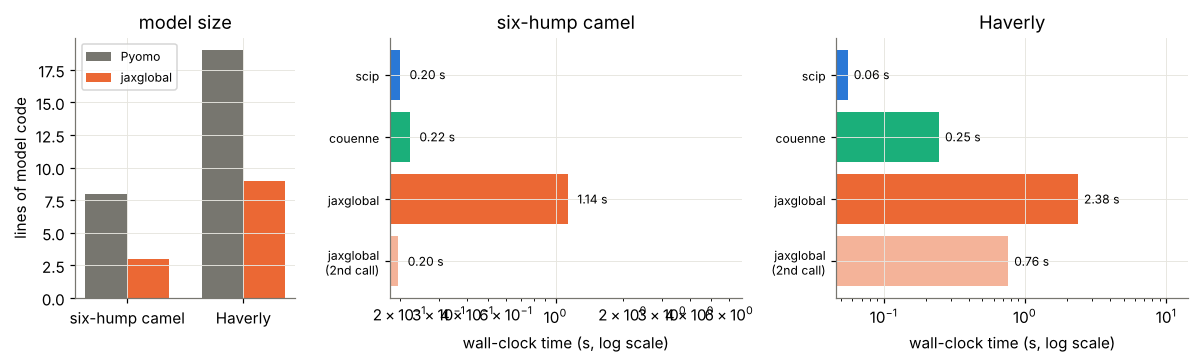

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
ax = axs[0]
locs = {"six-hump camel": (loc(camel_pyomo), loc(camel)), "Haverly": (lp, lj)}
xx = np.arange(2)
ax.bar(xx - 0.18, [v[0] for v in locs.values()], 0.36, color=MUTED, label="Pyomo")
ax.bar(xx + 0.18, [v[1] for v in locs.values()], 0.36, color=ORANGE, label="jaxglobal")
ax.set_xticks(xx, list(locs))
ax.set_ylabel("lines of model code")
ax.set_title("model size")
ax.legend(fontsize=8)

timing = {
    "six-hump camel": [(r["solver"], r["time"]) for r in camel_rows],
    "Haverly": [(r["solver"], r["time"]) for r in haverly_rows] + [("jaxglobal (2nd call, cached)", res_hav.time)],
}
for ax, (case, tt) in zip(axs[1:], timing.items()):
    tt = [(s, v) for s, v in tt if np.isfinite(v)]
    for i, (s, v) in enumerate(tt):
        col = STYLE[s.split()[0]][0]
        ax.barh(i, v, color=col, alpha=0.5 if "cached" in s else 1)
        ax.text(v * 1.1, i, f"{v:.2f} s", va="center", fontsize=8)
    ax.set_yticks(range(len(tt)), [s.replace(" (2nd call, cached)", "\n(2nd call)") for s, _ in tt], fontsize=8)
    ax.set_xscale("log")
    ax.set_xlim(right=max(v for _, v in tt) * 6)
    ax.invert_yaxis()
    ax.set_xlabel("wall-clock time (s, log scale)")
    ax.set_title(case)
plt.tight_layout()
plt.show()

## What was hard

Nothing. Both formulations are direct transcriptions of the algebra, and every solver that ran agrees on $-400$ (Haverly) and $-1.0316$ (camel).
Observations that matter for the rest of the series:

* **Line counts are similar.** Pyomo is a bit longer because of variable declarations, but it also gives you named variables and constraints for free. The JAX version has no names for constraints; you get an array of values and rely on comments and ordering.
* **Model size.** Pyomo's model has one variable per decision variable and one constraint object per equation, which is the same size as the algebra. This will not hold once the model contains loops or tables.
* **Tooling.** On these problems the mature solvers (SCIP, Couenne, and BARON where it is installed) are as fast as, or faster than, jaxglobal, which pays a JIT-compilation cost on first use; the cached second call removes most of that cost. By default jaxglobal's bounds are not rigorous in floating point; `minimize(..., safe=True)` rounds every bound outward (about 1.7× slower). It handles continuous and integer variables.
* **Fairness check passed.** Same optimum, same gap tolerance. Differences in later notebooks come from model structure, not from different problems.